In [1]:
###初始化数据
import pandas as pd
from sqlalchemy import create_engine
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns
import numpy as np
import os
from dotenv import load_dotenv

load_dotenv('密码.env') 

db_user = os.getenv("MYSQL_USER")
db_password = os.getenv("MYSQL_PASSWORD")
db_host = os.getenv("MYSQL_HOST")
db_port = os.getenv("MYSQL_PORT")
db_name = os.getenv("MYSQL_DB")

engine= create_engine(f'mysql+pymysql://{db_user}:{db_password}@{db_host}:{db_port}/{db_name}')



In [2]:
###1、用户行为转化漏斗分析

sql_clean= "SELECT * FROM user_behavior_clean LIMIT 10000"


df_clean=pd.read_sql(sql_clean,engine)
funnel_df = df_clean.groupby('behavior_type')['user_id'].nunique().reset_index()
funnel_df.columns = ['behavior_type', 'user_count']
order = ['pv', 'fav', 'cart', 'buy']
funnel_df['behavior_type'] = pd.Categorical(funnel_df['behavior_type'], categories=order, ordered=True)
funnel_df = funnel_df.sort_values('behavior_type')

print("=== 漏斗各环节独立用户数 ===")
pv_users = funnel_df[funnel_df['behavior_type'] == 'pv']['user_count'].values[0]
funnel_df['conversion_rate'] = (funnel_df['user_count'] / pv_users * 100).round(2)
print(funnel_df)
print(pv_users)

=== 漏斗各环节独立用户数 ===
  behavior_type  user_count  conversion_rate
3            pv          94           100.00
2           fav          37            39.36
1          cart          73            77.66
0           buy          60            63.83
94


-0.4 0.4
94 0.0
0.6 0.4
73 1.0
1.6 0.4
37 2.0
2.6 0.4
60 3.0


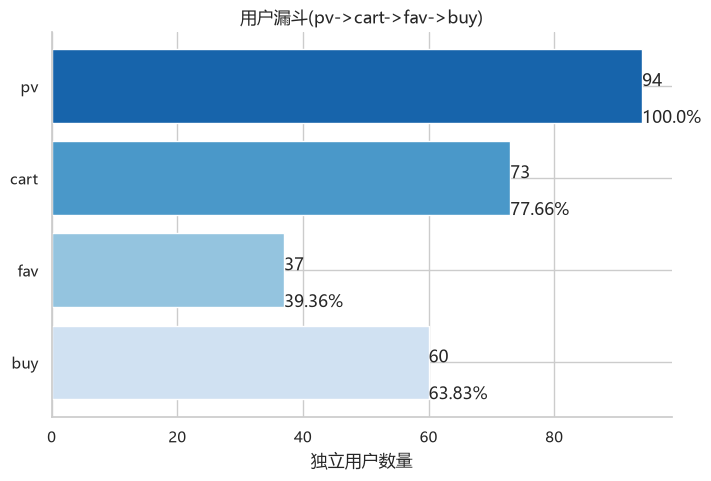

In [3]:

gpdc=df_clean.groupby('behavior_type')['user_id'].nunique().reset_index()
gpdc.columns=['behavior_type','user_count']
od2=['pv','cart','fav','buy']
gpdc['behavior_type']=pd.Categorical(gpdc['behavior_type'],categories=od2,ordered=True)
pv_use=gpdc['user_count'].values[3]
gpdc['con_rate']=round(gpdc['user_count']/pv_use*100,2)
gpdc=gpdc.sort_values('behavior_type')
plt.rcParams['font.sans-serif']=['Microsoft YaHei']
plt.rcParams['axes.unicode_minus']=False
sns.set_theme(style="whitegrid", font='Microsoft YaHei')
plt.figure(figsize=(8,5))
colors = sns.color_palette("Blues_r", len(gpdc))
ba=plt.barh(gpdc['behavior_type'], gpdc['user_count'], color=colors)
plt.xlabel('独立用户数量')
plt.title('用户漏斗(pv->cart->fav->buy)')
for j in ba:
    width=j.get_width()
    y=j.get_y()+j.get_height()/2
    print(j.get_y(),j.get_height()/2)
    print(width,y)
    plt.text(width,y,f'{int(width)}')
    plt.text(width,y+j.get_height()/2,f'{round(int(width)*100/pv_use,2)}%')
plt.gca().invert_yaxis()
sns.despine()
plt.show()

 图表说明：用户行为转化漏斗（柱状图版）
markdown
### 📊 图表分析说明：用户行为转化漏斗

- **分析目的**：通过横向柱状图直观展示用户从浏览商品到最终购买的转化过程，定位流失最严重的环节。
- **指标口径**：
  - **统计对象**：发生对应行为的**独立用户数（UV）**，而非行为总次数（PV）。
  - **漏斗顺序**：浏览（pv） -> 加购（cart）/ 收藏（fav） -> 购买（buy）。
  - **转化率计算**：以各环节的 UV 除以初始的“浏览（pv）”UV。
- **主要观察**：柱状图显示，从浏览到加购/收藏环节，用户数量出现显著下降（流失率约 22.34%/60.54%）；而从加购/收藏到最终购买，同样存在一定比例的用户流失。
- **业务解释与局限**：
  - **解释**：漏斗直观反映了用户在整个决策链路中的流失情况。加购环节流失高，说明商品详情页或价格敏感度影响了用户决策；购买环节流失，可能涉及运费或结算流程繁琐。
  - **局限**：该漏斗只统计了用户“是否发生过该行为”，是探索性转化漏斗，并未强制要求行为按“浏览->加购->购买”的严格时间顺序发生（即用户可能今天买完，明天又去浏览）。若要追踪严格顺序，需结合路径矩阵分析。

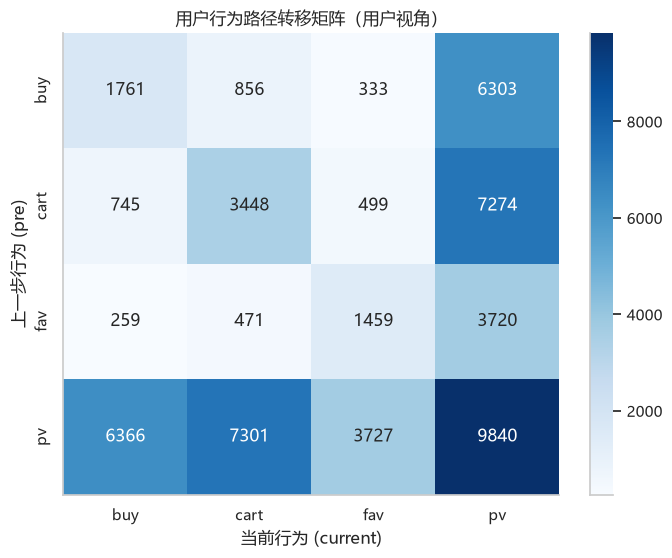

In [4]:
###2、用户整体行为路径转移矩阵分析
df_path = pd.read_sql("SELECT * FROM user_path_result", engine)
matrix = df_path.pivot_table(
    index='pre_behavior', 
    columns='behavior_type', 
    values='user_count', 
    fill_value=0
)
matrix = matrix.astype(int) 

plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
sns.set_theme(style="whitegrid", font='Microsoft YaHei')
plt.figure(figsize=(8, 6))
sns.heatmap(matrix, annot=True, fmt='d',cmap='Blues')
plt.title('用户行为路径转移矩阵（用户视角）')
plt.ylabel('上一步行为 (pre)')
plt.xlabel('当前行为 (current)')
sns.despine()
plt.show()

### 📊 图表分析说明：用户相邻行为路径转移矩阵

- **分析目的**：揭示用户在进行某一动作后，紧接着发生的下一步动作是什么。
- **指标口径**：使用 `LAG()` 窗口函数按 `user_id` 提取相邻行为。统计对象为发生转移的**独立用户数（UV）**。
- **主要观察**：`pv -> pv` 的流量最大（9,206人），其次为 `cart -> pv`（5,677人）；值得注意的是，`pv -> buy` 的用户数（4,515人）显著高于 `cart -> buy`（1,139人）。
- **业务解释与局限**：
  - **解释**：说明样本中“直接购买（未见加购过程）”的相邻路径占比较高，同时加购后的用户容易回撤到浏览环节。
  - **局限**：此分析仅基于“相邻”两步行为，不能代表完整的用户决策旅程（例如用户可能经历了多次 pv->cart->pv 循环），因此不能直接等同为“购物车流失”或绝对意义上的“冲动消费”。

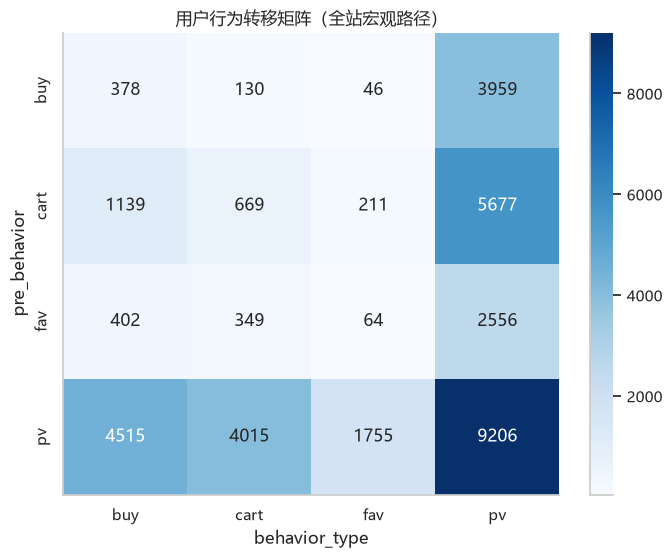

In [5]:
###3、用户行为路径转移矩阵（全局宏观版）
sql_clean_path = """
WITH item_path AS (
    SELECT
        user_id,
        item_id,
        category_id,
        behavior_type,
        ts,
        LAG(behavior_type) OVER (
            PARTITION BY user_id, item_id
            ORDER BY ts
        ) AS pre_behavior
    FROM user_behavior_clean
)
SELECT
    pre_behavior,
    behavior_type,
    COUNT(*) AS transition_count,
    COUNT(DISTINCT user_id, item_id) AS user_item_pair_count,
    COUNT(DISTINCT user_id) AS user_count
FROM item_path
WHERE pre_behavior IS NOT NULL
GROUP BY pre_behavior, behavior_type
ORDER BY transition_count DESC;
"""
df_clean_path = pd.read_sql(sql_clean_path, engine)
matrix_path = df_clean_path.pivot_table(
    index='pre_behavior', 
    columns='behavior_type', 
    values='user_count', 
    fill_value=0
).astype(int)

sns.set_theme(style="whitegrid", font='Microsoft YaHei')
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.figure(figsize=(8, 6))
sns.heatmap(matrix_path, annot=True, fmt='d', cmap='Blues') 
plt.title('用户行为转移矩阵（全站宏观路径）')
sns.despine()
plt.show()

图表分析说明：用户行为转移矩阵（全站宏观路径）

分析目的：脱离具体商品限制，从全站（大盘）视角探究用户在执行某一动作后，下一步紧接着会去做什么，从而发现流量流转的宏观规律和关键节点。

指标口径：

使用 LAG() 窗口函数按 user_id 分组并按时间排序，提取用户的“上一步行为（pre_behavior）”。

统计对象为发生该“相邻行为对”的独立用户数（UV）。

仅统计有前序行为的记录（过滤掉了用户的第一次动作）。

主要观察：

矩阵中颜色最深、流量最大的是 pv -> pv（9,206 人），说明用户在平台上最主要的行为是“连续浏览”。

cart -> pv（5,677 人）的流量显著高于 cart -> buy（1,139 人），说明用户在加购后，大概率会返回浏览页面。

pv -> buy（4,515 人）的独立用户数明显多于加购后购买的用户数。

业务解释与局限：

解释：高企的 cart -> pv 路径说明购物车在用户决策链路中更倾向于是“暂存区”而非“结算终点”；大量的 pv -> buy 表明平台存在较强的一键直购或冲动直购场景。

局限：该矩阵仅统计了相邻两步的行为转移，无法还原用户完整的复杂决策旅程（如：加购后又去浏览，最终才购买的长链路）。同时，绝对值受制于各行为本身的发生频率（浏览天然多于购买），因此不能将绝对人数的差异直接等同于“转化概率”的差异。

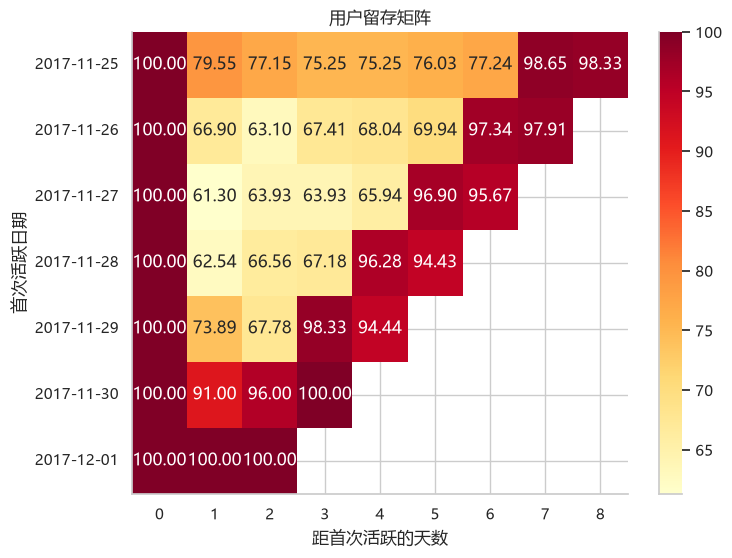

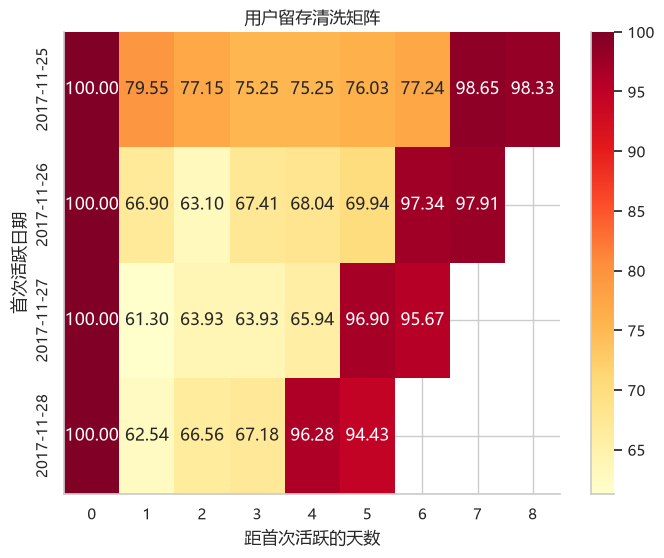

In [6]:
###4、生存分析与返回分析

sql_save=""" WITH user_cohort AS (
    SELECT 
        user_id,
        date(MIN(event_time)) AS cohort_date
    FROM user_behavior_clean
    GROUP BY user_id
)
SELECT 
    b.user_id,
    a.cohort_date,
    coalesce(DATEDIFF(DATE(b.event_time), a.cohort_date),0) AS period_day
FROM user_cohort a
JOIN user_behavior_clean b ON a.user_id = b.user_id
/*WHERE behavior_type='buy'*/
;
"""
df_user_c=pd.read_sql(sql_save,engine)#

cohort_counts = df_user_c.groupby(['cohort_date', 'period_day'])['user_id'].nunique().reset_index()
cohort_counts.columns = ['cohort_date', 'period_day', 'user_count']

cohort_matrix = cohort_counts.pivot_table(
    index='cohort_date', 
    columns='period_day', 
    values='user_count', 
    fill_value=0
).astype(int)


data_end = pd.Timestamp('2017-12-03')


cohort_size = cohort_matrix[0]


cohort_matrix_observed = cohort_matrix.astype(float).copy()

for cohort_date in cohort_matrix_observed.index:
    max_observed_period = (
        data_end - pd.Timestamp(cohort_date).normalize()
    ).days

    future_periods = (
        cohort_matrix_observed.columns > max_observed_period
    )

    cohort_matrix_observed.loc[
        cohort_date, future_periods
    ] = np.nan


retention_matrix = (
    cohort_matrix_observed.div(cohort_size, axis=0) * 100
).round(2)


min_cohort_size = 300
keep_cohorts = cohort_size > min_cohort_size

cohort_matrix_clean = cohort_matrix_observed.loc[keep_cohorts]
cohort_size_clean = cohort_size.loc[keep_cohorts]


retention_matrix_clean = (
    cohort_matrix_clean.div(cohort_size_clean, axis=0) * 100
).round(2)

def plot_retention(matrix, title):
    plt.figure(figsize=(8, 6))
    sns.set_theme(style="whitegrid", font='Microsoft YaHei')
    sns.heatmap(
        matrix,
        mask=matrix.isna(),
        annot=True,
        fmt='.2f',
        cmap='YlOrRd'
    )
    sns.despine()
    plt.title(title)
    plt.xlabel('距首次活跃的天数')
    plt.ylabel('首次活跃日期')
    plt.show()


plot_retention(retention_matrix, '用户留存矩阵')
plot_retention(retention_matrix_clean, '用户留存清洗矩阵')

📊 图表分析说明：用户留存矩阵与清洗后矩阵
分析目的：观察不同首日活跃群体（Cohort）随时间的留存衰减情况，评估样本用户的粘性，并通过小样本清洗和未观测周期遮罩，还原真实留存趋势。

指标口径：

计算公式：留存率 = （特定 Cohort 在第 N 天活跃的独立用户数 / 该 Cohort 首日总活跃人数）* 100%。

清洗逻辑：

剔除首日用户数小于 300 的 Cohort，避免小样本带来的比例失真。
将超出观测截止日（2017-12-03）的“未来周期”设为 NaN 并用热力图遮罩（灰色区域），防止误导。
主要观察：

清洗后的主力 Cohort（11-25 至 11-28）表现平稳，Day 1 留存率普遍在 60%-80% 之间。

观察中后期，部分 Cohort 的留存率出现反弹现象（例如 11-27 的 Cohort 在 Day 4-6 期间留存率回升至 95% 以上）。

业务解释与局限：

解释：如此高的留存率印证了样本用户具有极高频的活跃特征（大多为浏览行为）；中后期的留存回升，可能受特定大促节点（如周末或双十二预热）的召回影响。

局限：由于数据集仅覆盖 9 天，该矩阵仅反映短期活跃趋势，无法评估长期留存（如 Day 30）。此外，当前口径未严格限定行为类型（包含大量 pv），属于“全行为留存”，并非纯“购买留存”。


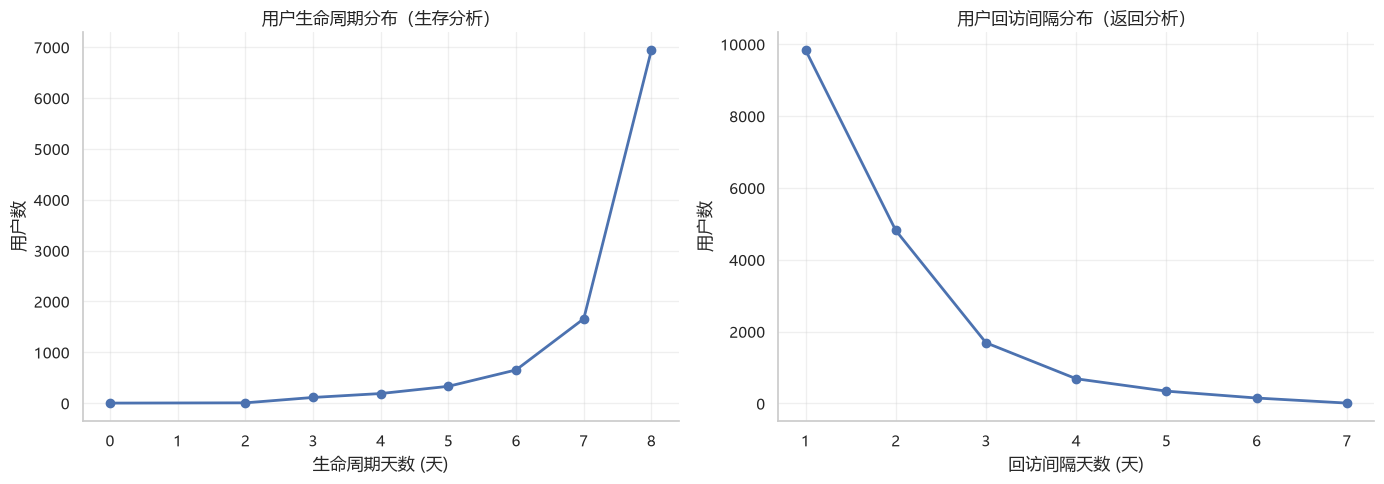

In [7]:
###五、留存矩阵清洗与分析
#
sql_life_1="""WITH user_lifespan AS (
    SELECT
        user_id,
        DATE(MIN(event_time)) AS first_active_date,
        DATE(MAX(event_time)) AS last_active_date,
        DATEDIFF(DATE(MAX(event_time)), DATE(MIN(event_time))) AS lifespan_days
    FROM user_behavior_clean
    GROUP BY user_id
)
SELECT
    lifespan_days,
    COUNT(DISTINCT user_id) AS user_count
FROM user_lifespan
GROUP BY lifespan_days
ORDER BY lifespan_days;

"""


#
sql_life_2="""WITH user_visit_days AS (
    SELECT DISTINCT user_id, DATE(event_time) AS visit_date
    FROM user_behavior_clean
),
user_lag AS (
    SELECT
        user_id,
        visit_date,
        LAG(visit_date) OVER (PARTITION BY user_id ORDER BY visit_date) AS prev_visit_date
    FROM user_visit_days
)
SELECT
    DATEDIFF(visit_date, prev_visit_date) AS return_gap_days,
    COUNT(DISTINCT user_id) AS user_count
FROM user_lag
WHERE prev_visit_date IS NOT NULL
GROUP BY return_gap_days
ORDER BY return_gap_days;

"""

df_life=pd.read_sql(sql_life_1,engine)#
df_user_visit_days=pd.read_sql(sql_life_2,engine)#


plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
sns.set_theme(style="whitegrid", font='Microsoft YaHei')
fig, axes = plt.subplots(1, 2, figsize=(14, 5))


axes[0].plot(df_life['lifespan_days'], df_life['user_count'], marker='o', color='#4C72B0', linewidth=2)
axes[0].set_title('用户生命周期分布（生存分析）')
axes[0].set_xlabel('生命周期天数 (天)')
axes[0].set_ylabel('用户数')
axes[0].grid(alpha=0.3)


axes[1].plot(df_user_visit_days['return_gap_days'], df_user_visit_days['user_count'], marker='o', color='#4C72B0', linewidth=2)
axes[1].set_title('用户回访间隔分布（返回分析）')
axes[1].set_xlabel('回访间隔天数 (天)')
axes[1].set_ylabel('用户数')
axes[1].grid(alpha=0.3)
sns.despine()
plt.tight_layout()
plt.show()

### 📊 图表分析说明：用户生命周期与回访间隔分布

- **分析目的**：观察样本用户在观测期内的活跃时间跨度（生存分析）以及活跃频率（返回分析）。
- **指标口径**：
  - **生命周期**：最后一次活跃日期 - 首次活跃日期（天）。
  - **回访间隔**：本次活跃日期 - 上一次活跃日期（天）。
- **主要观察**：生命周期为 8 天的用户数量最多（6,944人）；回访间隔中，间隔 1 天的用户高达 9,838 人，随后呈断崖式下跌。
- **业务解释与局限**：说明该样本群体具有极高的每日活跃度。局限性在于受制于仅 9 天的数据窗口，“生命周期”数据被严重右截断（最大仅为 8 天），无法反映用户真实的最终流失周期。